
# Horse Training Data Analysis and Visualization

This Jupyter Notebook focuses on analyzing and visualizing horse training data using metrics derived from a JSON dataset. The primary objectives include:

1. **Data Processing**:

   * Load and parse a JSON file containing horse training data.
   * Sort and clean the data for visualization and analysis.

2. **Visualization of Metrics**:

   * **Trot Distance Load**: Visualize the daily trot distance load for each horse over time, both individually and in subplots for all horses.
   * **ACWR Metrics**: Analyze and plot Acute\:Chronic Workload Ratio (ACWR) metrics for:

     * Distance
     * Duration
     * iTrimp (internal training load)
   * Highlight risk categories (e.g., undertraining, optimal, overreaching, overtraining) based on ACWR thresholds.

3. **Combined ACWR Comparison**:

   * Compare multiple ACWR metrics (Distance, Duration, iTrimp) for each horse in a single plot.

4. **Feedback Generation Using Ollama + Local LLM**:

   * Summarize training load and ACWR values over recent weeks for a selected horse.
   * Generate **expert-style personalized feedback** for the trainer using a **locally hosted large language model** (LLM) such as **Mistral**, executed through the `ollama` CLI.
   * The model processes a structured summary and produces clear, supportive recommendations based on workload balance and gait-specific activity patterns.

This notebook uses Python libraries such as `pandas`, `matplotlib`, and `seaborn` for data manipulation and visualization, along with `subprocess` for interacting with the local model. The combined analytics and AI-driven feedback aim to provide **actionable insights into horse training performance**, enabling more informed and individualized workload management.

---


In [1]:
import json
import pandas as pd

# Use relative path to the file
path_horse_readiness_json = "datasets/Horse_Readiness_FULLY_FIXED.json"


with open(path_horse_readiness_json, "r", encoding="utf-8") as f:
    data = json.load(f)

records = []

for entry in data:
    horse_id = entry.get("HorseID", "unknown")
    acwr = entry.get("ACWR", {})

    for date, metrics in acwr.items():
        flat_record = {"HorseID": horse_id, "Date": date}

        for category, submetrics in metrics.items():
            for subname, values in submetrics.items():
                for k, v in values.items():
                    column_name = f"{category}_{subname}_{k}"
                    flat_record[column_name] = float(v) if v.replace('.', '', 1).isdigit() else v

        records.append(flat_record)

df = pd.DataFrame(records)

df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df.sort_values(["HorseID", "Date"], inplace=True)

display(df.sample(4))

,HorseID,Date,externalDistance_Distance_Load_Today,externalDistance_Distance_sevenDay_Total,externalDistance_Distance_AW,externalDistance_Distance_CW,externalDistance_Distance_ACWR,externalDistance_Walk_Distance_Load_Today,externalDistance_Walk_Distance_sevenDay_Total,externalDistance_Walk_Distance_AW,...,iTrimp_canter_Load_Today,iTrimp_canter_sevenDay_Total,iTrimp_canter_AW,iTrimp_canter_CW,iTrimp_canter_ACWR,iTrimp_galop_Load_Today,iTrimp_galop_sevenDay_Total,iTrimp_galop_AW,iTrimp_galop_CW,iTrimp_galop_ACWR
2443,602,2025-01-18,7.79,33.84,35.93,30.59,1.17,1.73,8.24,9.47,...,0.40,0.61,3.90,2.90,1.34,0.00,21.50,22.71,24.33,0.93
1372,311,2023-11-25,0.00,4.61,7.81,15.06,0.52,0.00,1.65,3.65,...,0.00,0.00,0.79,3.81,0.21,0.00,0.00,0.02,0.19,0.11
1265,311,2023-08-09,6.23,16.97,16.81,22.60,0.74,1.05,3.92,4.94,...,2.82,5.24,3.43,6.09,0.56,0.00,0.00,0.62,1.07,0.58
1526,311,2024-04-27,11.34,36.68,40.30,32.58,1.24,3.32,13.24,15.75,...,0.00,6.74,9.52,6.20,1.54,2.73,2.73,0.82,0.37,2.22


## Combined ACWR Comparison Plot per Horse

In this part of visualization we are combining the ACWR from three main metrics from json file such as `Distance`, `Duration`, `ITrimp` to see if there are any big differences between them.

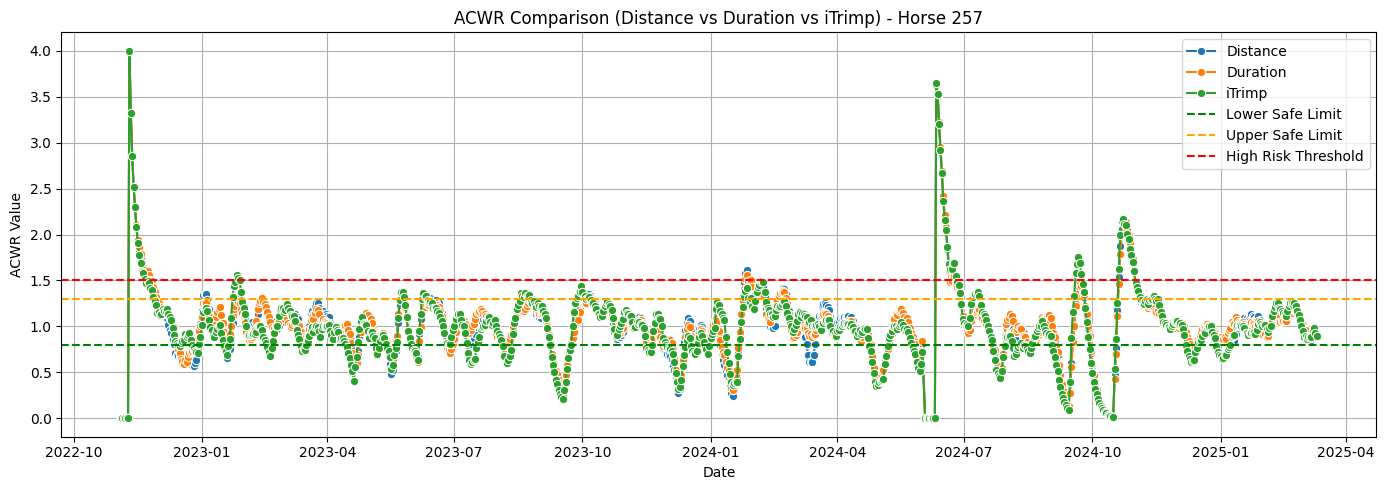

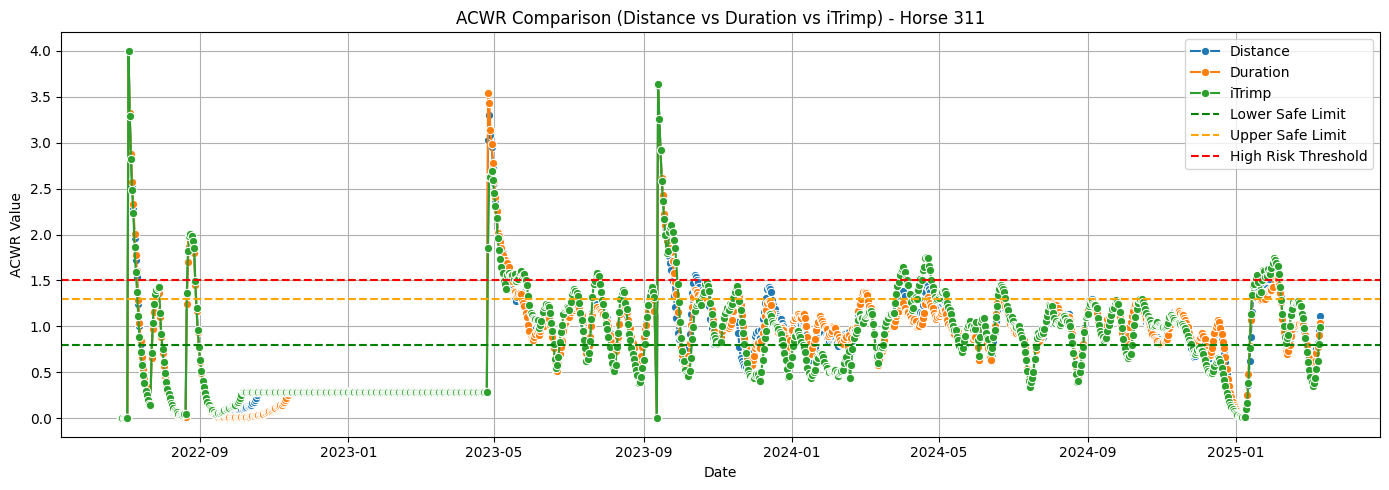

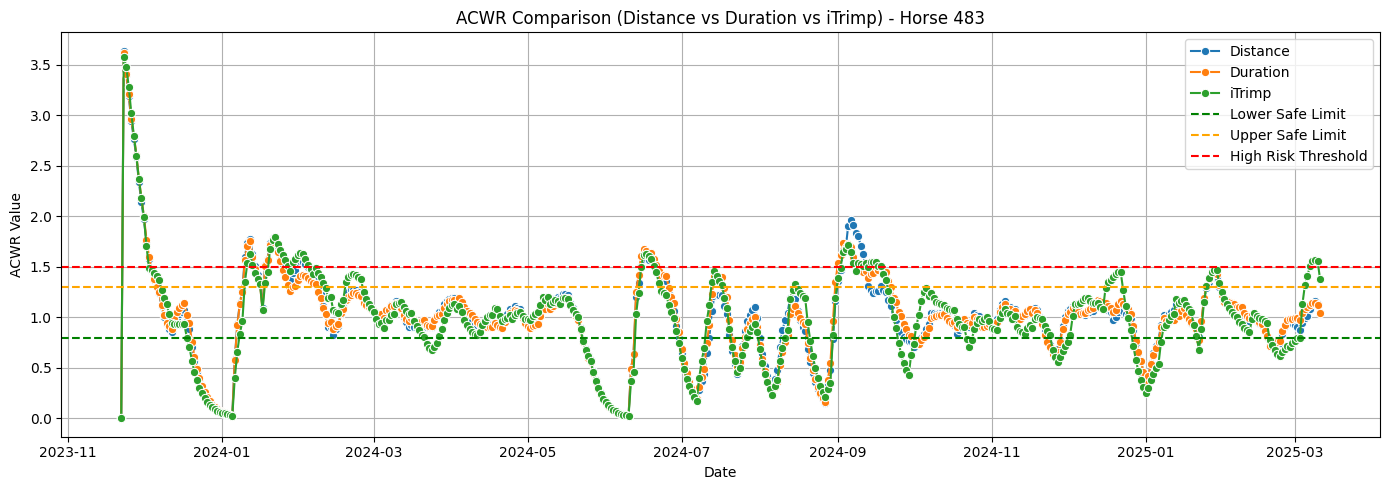

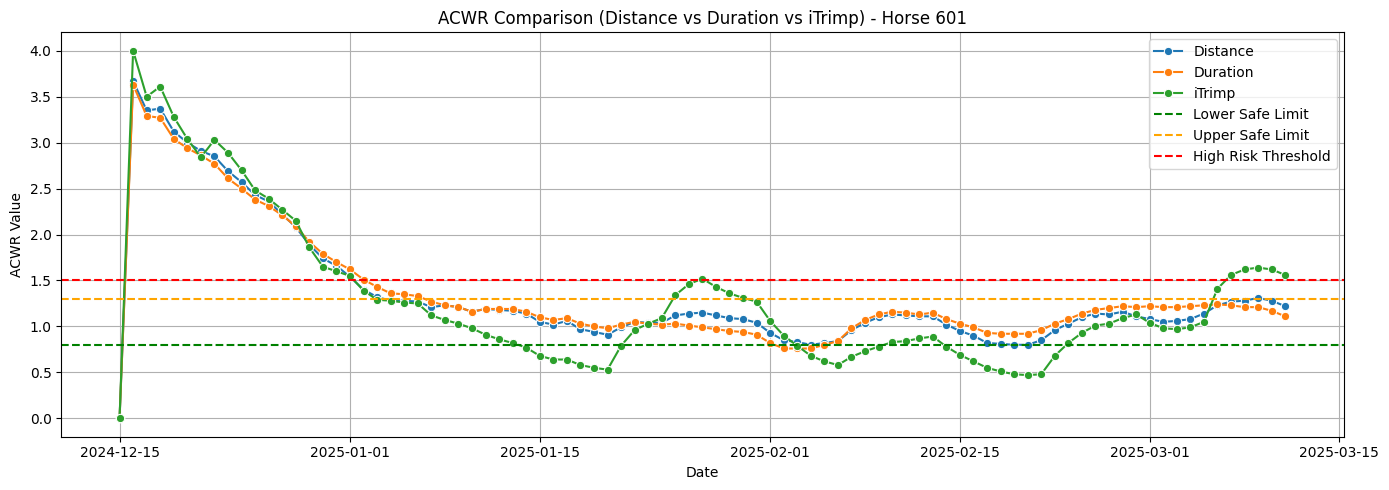

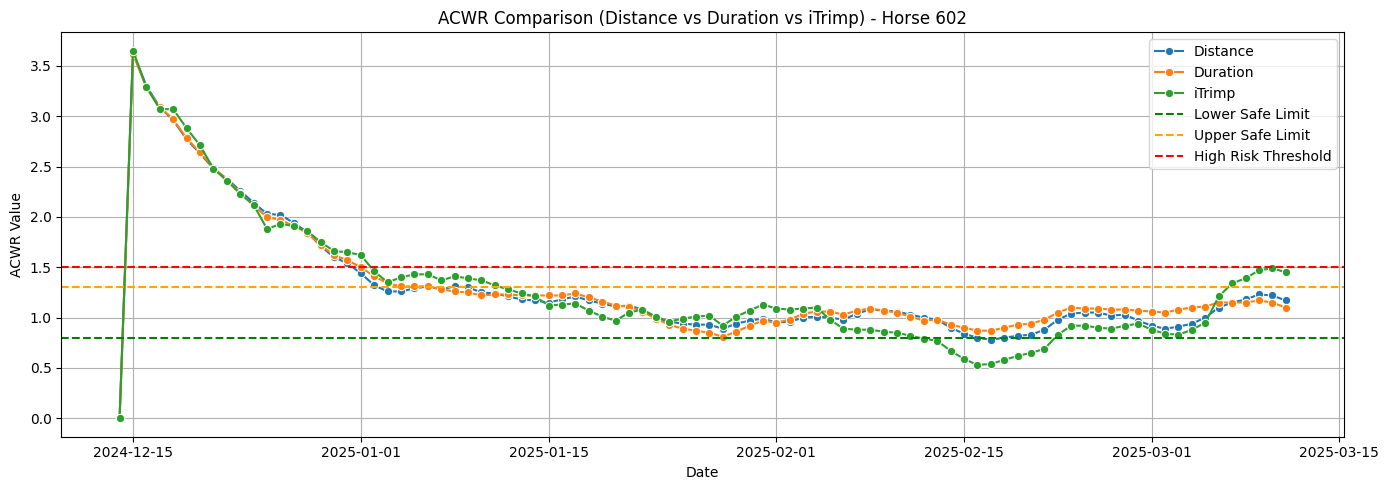

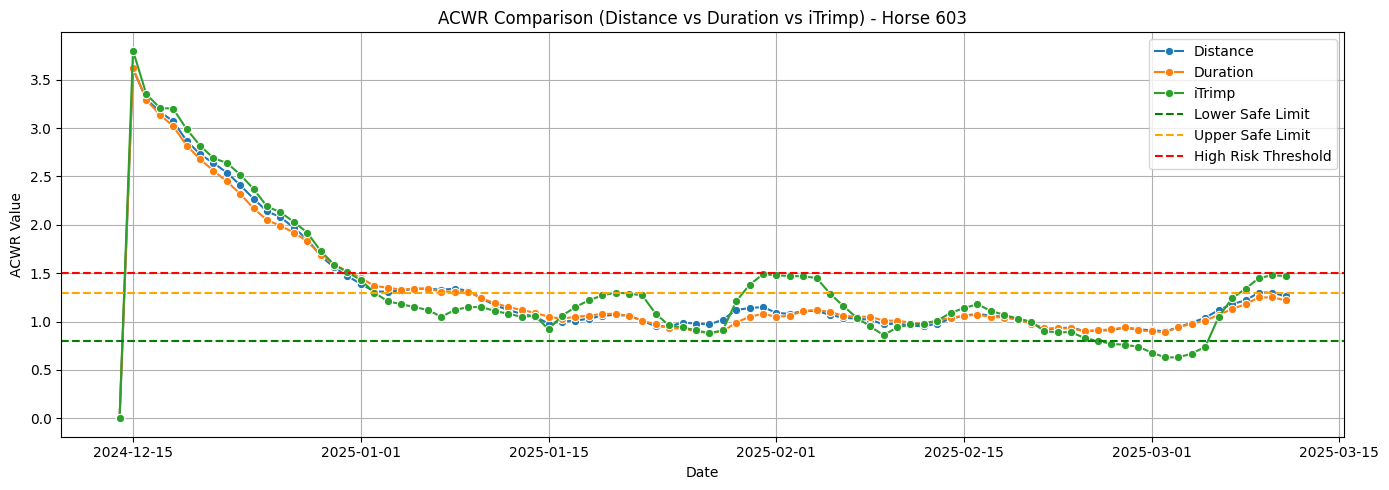

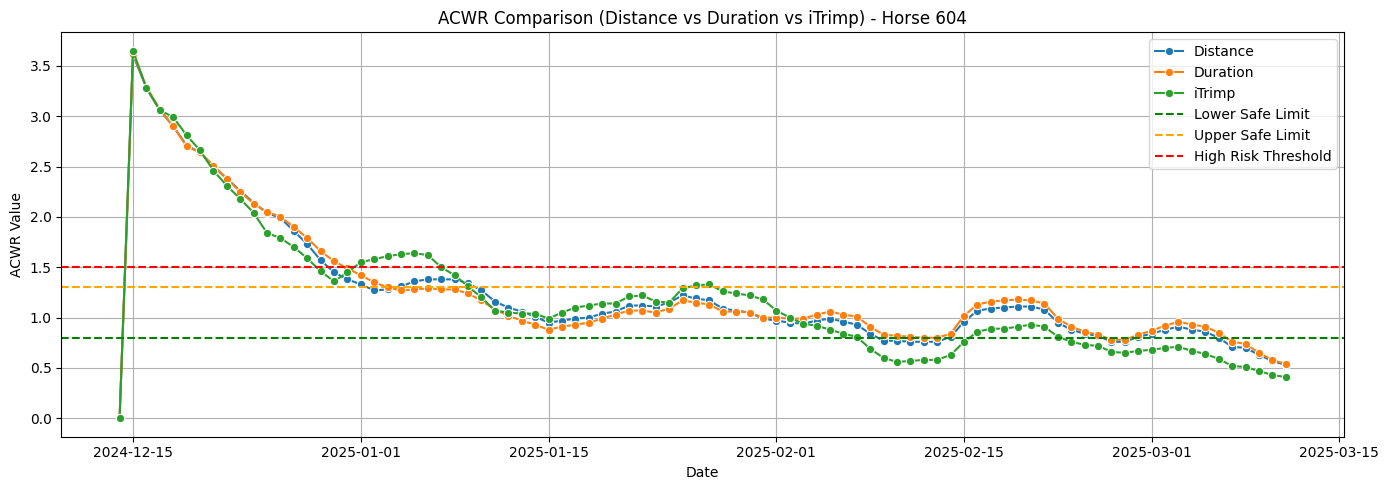

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the 3 ACWR metric columns
acwr_cols = {
    'Distance': 'externalDistance_Distance_ACWR',
    'Duration': 'externalDuration_Duration_ACWR',
    'iTrimp': 'iTrimp_overall_ACWR'
}

# Prepare data: keep only relevant columns
acwr_df = df[['HorseID', 'Date'] + list(acwr_cols.values())].dropna()

# Convert to float
for col in acwr_cols.values():
    acwr_df[col] = acwr_df[col].astype(float)

# Melt to long format for seaborn
df_melted = acwr_df.melt(id_vars=['HorseID', 'Date'], 
                         value_vars=acwr_cols.values(), 
                         var_name='ACWR_Type', 
                         value_name='ACWR_Value')

# Optional: map technical column names to readable ones
df_melted['ACWR_Type'] = df_melted['ACWR_Type'].map({
    'externalDistance_Distance_ACWR': 'Distance',
    'externalDuration_Duration_ACWR': 'Duration',
    'iTrimp_overall_ACWR': 'iTrimp'
})

# Get unique horses
horses = df_melted['HorseID'].unique()

# Plot all three metrics for each horse
for horse_id in horses:
    horse_df = df_melted[df_melted['HorseID'] == horse_id]

    plt.figure(figsize=(14, 5))
    sns.lineplot(data=horse_df, x='Date', y='ACWR_Value', hue='ACWR_Type', marker='o')
     
    # Thresholds
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold')

    plt.title(f'ACWR Comparison (Distance vs Duration vs iTrimp) - Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR Value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


After analysis we can see that `Duration` and `Distance` correlate to each other and follow the same pattern for each horse. `ITrimp` however does seem to fluctuate around but still keep the trending of the training exercises which give us conclusion that `Itrimp` might be the best metric to focus on since it represent how horse feels during those exercises and that is what we need to know.

## Data cleaning
Thanks to our client we go to realize that the weird spike up at the beggining of each horse measurement is just how ACWR imbalance calculations since it comare everything to previous weeks which were. To prevent this we are going to drop the first 4 weeks for every horse, since they are not correct data.

In [3]:
one_month_cutoff = df.groupby('HorseID')["Date"].transform(
    lambda s: s.min() + pd.DateOffset(months=1)   # earliest date + 1 month
)

df_clean = df[df["Date"] >= one_month_cutoff].copy()

df_clean.head(2)

,HorseID,Date,externalDistance_Distance_Load_Today,externalDistance_Distance_sevenDay_Total,externalDistance_Distance_AW,externalDistance_Distance_CW,externalDistance_Distance_ACWR,externalDistance_Walk_Distance_Load_Today,externalDistance_Walk_Distance_sevenDay_Total,externalDistance_Walk_Distance_AW,...,iTrimp_canter_Load_Today,iTrimp_canter_sevenDay_Total,iTrimp_canter_AW,iTrimp_canter_CW,iTrimp_canter_ACWR,iTrimp_galop_Load_Today,iTrimp_galop_sevenDay_Total,iTrimp_galop_AW,iTrimp_galop_CW,iTrimp_galop_ACWR
30,257,2022-12-04,7.02,38.37,35.25,30.47,1.16,1.0,9.72,9.80,...,6.37,15.06,10.45,9.57,1.09,0.0,0.0,0.0,0.0,0.0
31,257,2022-12-05,0.00,31.71,34.37,30.56,1.12,0.0,8.30,9.43,...,0.00,12.41,10.94,9.77,1.12,0.0,0.0,0.0,0.0,0.0


### One Plot for each horse

This plot showcases `ITrimp` of each horse after data cleaning. 

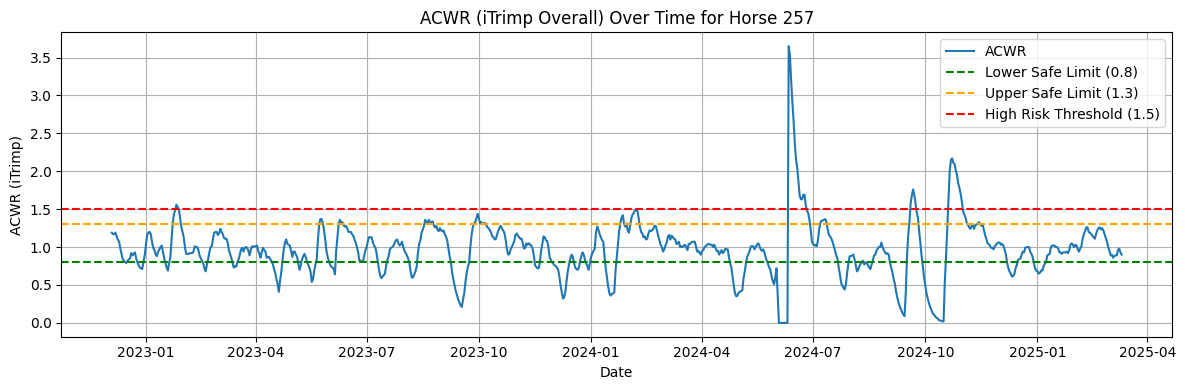

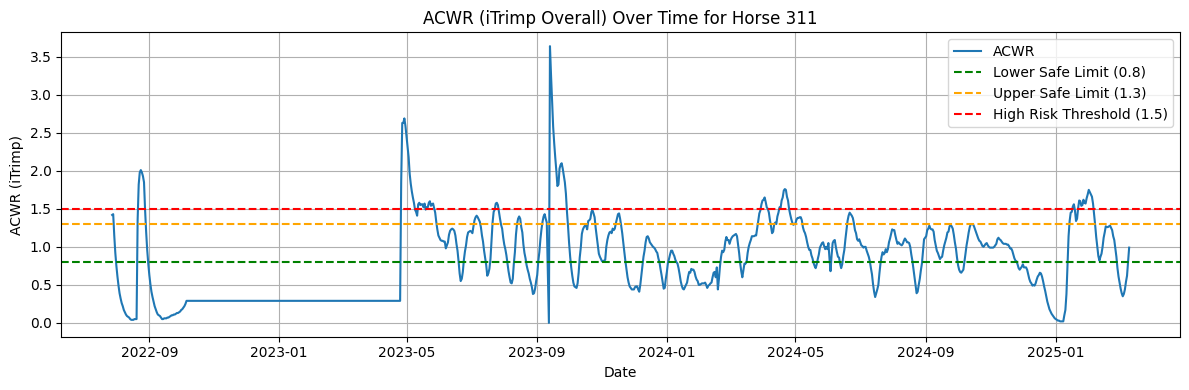

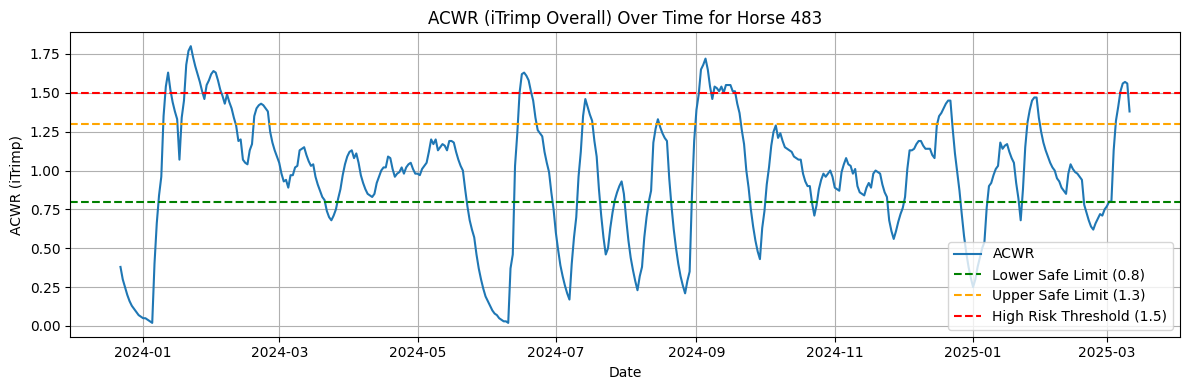

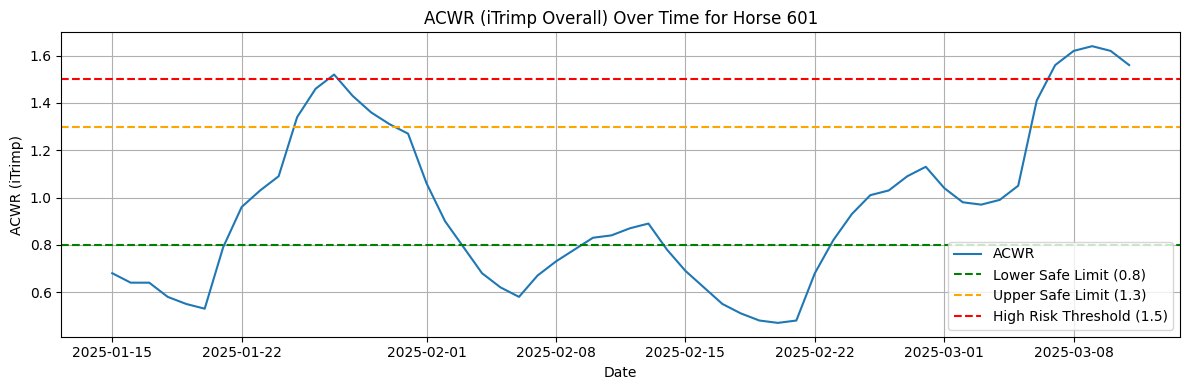

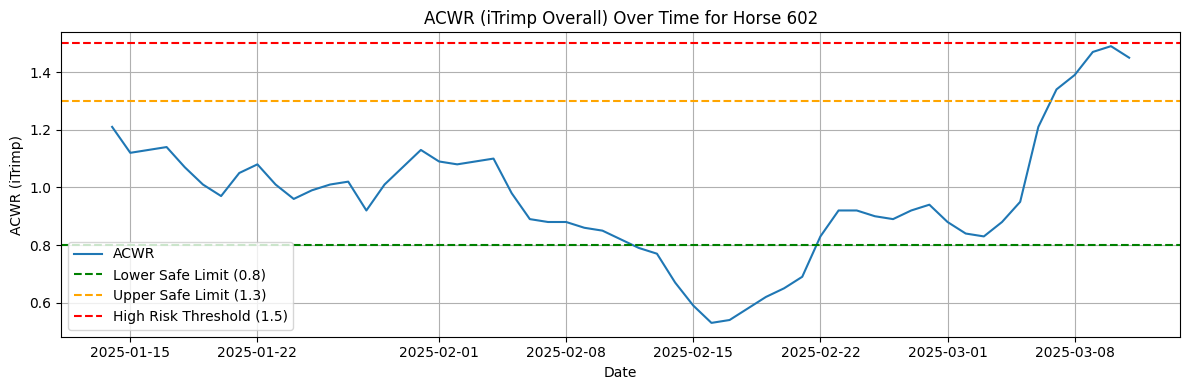

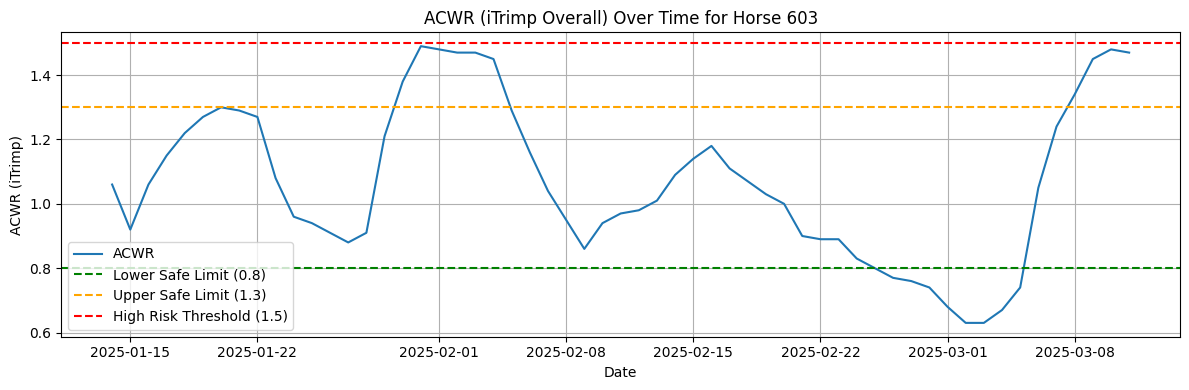

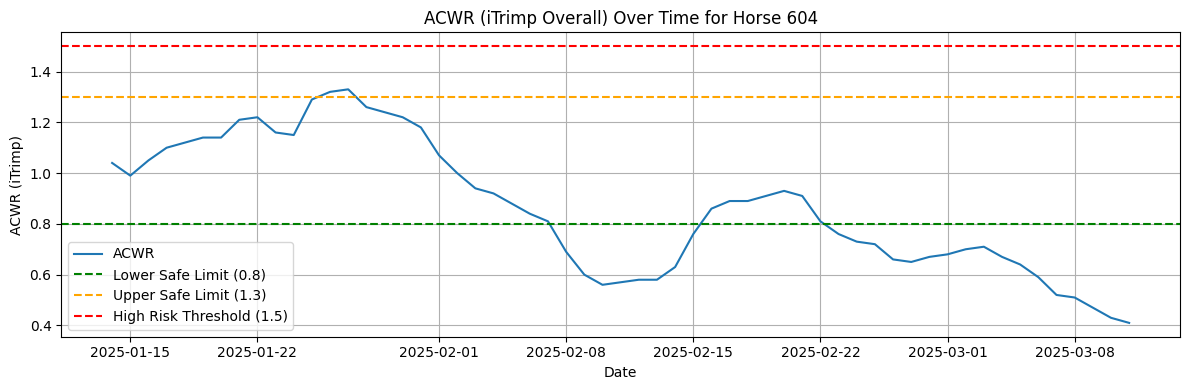

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ACWR metric for internal training load
acwr_col = 'iTrimp_overall_ACWR'

# Filter and clean
df_acwr = df_clean[['HorseID', 'Date', acwr_col]].dropna()
df_acwr[acwr_col] = df_acwr[acwr_col].astype(float)

# Optional: tag risk levels
df_acwr['ACWR_Risk'] = pd.cut(
    df_acwr[acwr_col],
    bins=[-float('inf'), 0.8, 1.3, 1.5, float('inf')],
    labels=['Undertraining', 'Optimal', 'Overreaching', 'Overtraining']
)

# Plot for each horse
horses = df_acwr['HorseID'].unique()

for horse_id in horses:
    horse_df = df_acwr[df_acwr['HorseID'] == horse_id]

    plt.figure(figsize=(12, 4))
    sns.lineplot(data=horse_df, x='Date', y=acwr_col, label='ACWR')
    
    # ACWR safe zone lines
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit (0.8)')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit (1.3)')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold (1.5)')
    
    plt.title(f'ACWR (iTrimp Overall) Over Time for Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR (iTrimp)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## Generating Feedback with the Ollama Model

In this section, a large language model (LLM) is used to generate professional feedback for horse trainers based on recent ACWR (Acute:Chronic Workload Ratio) summaries. The approach involves:

- Summarizing the latest ACWR metrics and trends for a selected horse.
- Sending this summary as a prompt to the Ollama model (using the Mistral LLM) via a local command-line interface.
- Automatically generating a concise, expert-level feedback message tailored to the horse's recent workload and risk profile.


In [16]:
horse_id = "311"  # choose one horse
df_horse = df_clean[df_clean["HorseID"] == horse_id].copy()

# Define relevant columns
columns_to_include = [
    "Date",

    # Load_Today
    "iTrimp_overall_Load_Today",
    "iTrimp_walk_Load_Today",
    "iTrimp_trot_Load_Today",
    "iTrimp_canter_Load_Today",
    "iTrimp_galop_Load_Today",

    # ACWR
    "iTrimp_overall_ACWR",
    "iTrimp_walk_ACWR",
    "iTrimp_trot_ACWR",
    "iTrimp_canter_ACWR",
    "iTrimp_galop_ACWR",
]

# Filter out rows with missing values in any of those columns
df_horse = df_horse[columns_to_include].dropna()

# Convert ACWR columns to float (if needed)
acwr_columns = [col for col in columns_to_include if "ACWR" in col]
df_horse[acwr_columns] = df_horse[acwr_columns].astype(float)

df_horse.head(3)


,Date,iTrimp_overall_Load_Today,iTrimp_walk_Load_Today,iTrimp_trot_Load_Today,iTrimp_canter_Load_Today,iTrimp_galop_Load_Today,iTrimp_overall_ACWR,iTrimp_walk_ACWR,iTrimp_trot_ACWR,iTrimp_canter_ACWR,iTrimp_galop_ACWR
888,2022-07-28,0.0,0.0,0.0,0.0,0.0,1.42,1.29,1.39,1.76,0.08
889,2022-07-29,0.0,0.0,0.0,0.0,0.0,1.43,1.31,1.39,1.72,0.08
890,2022-07-30,0.0,0.0,0.0,0.0,0.0,1.15,1.06,1.13,1.38,0.09


In [17]:
import subprocess
import json

def generate_local_feedback(summary_text):
    prompt = f"""
You are an equine sports scientist. Based on the horse's training data, write a short and helpful feedback message for the trainer. Use a professional and supportive tone.

The data includes:
- Date
- Training Load (Load)
- ACWR (Acute:Chronic Workload Ratio)
- Zone (training quality: undertrained, optimal, overtrained)

Guidelines:
- Comment on the overall training balance.
- Point out gaits that are undertrained or overtrained (based on Zone).
- Note that some days have Load = 0 (recovery days).
- Give clear advice on adjusting training or giving rest.

Provide only the feedback with explanations. No summaries.


--- Training Summary Start ---
{summary_text}
--- Training Summary End ---

Trainer Feedback:
"""
    
    # Send to Ollama (CLI mode)
    result = subprocess.run(
        ['ollama', 'run', 'mistral'],
        input=prompt.encode(),
        stdout=subprocess.PIPE
    )

    output = result.stdout.decode('utf-8')
    return output.strip()



In [18]:
from datetime import timedelta

def get_risk_zone(acwr):
    if acwr < 0.8:
        return "Undertrained"
    elif acwr > 1.5:
        return "Overtrained"
    else:
        return "Optimal"

def summarize_recent_7_days(df_horse):
    df_recent = df_horse.sort_values("Date").tail(7)
    summary = "Recent 7 Days Training Summary:\n"

    for _, row in df_recent.iterrows():
        summary += f"{row['Date'].strftime('%Y-%m-%d')}:\n"
        for gait in ["walk", "trot", "canter", "galop"]:
            load = row[f"iTrimp_{gait}_Load_Today"]
            acwr = row[f"iTrimp_{gait}_ACWR"]
            zone = get_risk_zone(acwr) if load > 0 else "Not Trained"
            summary += f"  {gait.capitalize()} - Load: {load:.1f} | ACWR: {acwr:.2f} | Zone: {zone}\n"
    return summary

def summarize_weekly_averages(df_horse):
    df_sorted = df_horse.sort_values("Date")
    df_sorted['Week'] = df_sorted['Date'].dt.to_period('W').apply(lambda r: r.start_time)

    weeks = sorted(df_sorted['Week'].unique())[-6:-1]  # Previous 5 full weeks

    summary = "\nPrevious 5 Weeks Overview:\n"

    for week_start in weeks:
        week_data = df_sorted[df_sorted['Week'] == week_start]
        if len(week_data) == 0:
            continue
        avg_load = week_data["iTrimp_overall_Load_Today"].mean()
        avg_acwr = week_data["iTrimp_overall_ACWR"].mean()
        zone = get_risk_zone(avg_acwr)
        week_end = week_start + timedelta(days=6)
        summary += f"Week ({week_start.date()} to {week_end.date()}): Avg Load: {avg_load:.1f} | Avg ACWR: {avg_acwr:.2f} | Zone: {zone}\n"
    return summary

# Make sure Date column is datetime
df_horse["Date"] = pd.to_datetime(df_horse["Date"])

# Generate the summary text
summary_text = summarize_recent_7_days(df_horse) + "\n" + summarize_weekly_averages(df_horse)
print(summary_text)


Recent 7 Days Training Summary:
2025-03-05:
  Walk - Load: 0.0 | ACWR: 0.31 | Zone: Not Trained
  Trot - Load: 0.0 | ACWR: 0.47 | Zone: Not Trained
  Canter - Load: 0.0 | ACWR: 0.31 | Zone: Not Trained
  Galop - Load: 0.0 | ACWR: 0.15 | Zone: Not Trained
2025-03-06:
  Walk - Load: 0.3 | ACWR: 0.30 | Zone: Undertrained
  Trot - Load: 1.3 | ACWR: 0.62 | Zone: Undertrained
  Canter - Load: 0.3 | ACWR: 0.37 | Zone: Undertrained
  Galop - Load: 0.0 | ACWR: 0.14 | Zone: Not Trained
2025-03-07:
  Walk - Load: 0.1 | ACWR: 0.31 | Zone: Undertrained
  Trot - Load: 0.2 | ACWR: 0.75 | Zone: Undertrained
  Canter - Load: 1.8 | ACWR: 0.93 | Zone: Optimal
  Galop - Load: 0.0 | ACWR: 0.12 | Zone: Not Trained
2025-03-08:
  Walk - Load: 0.5 | ACWR: 0.35 | Zone: Undertrained
  Trot - Load: 1.4 | ACWR: 0.92 | Zone: Optimal
  Canter - Load: 0.1 | ACWR: 1.27 | Zone: Optimal
  Galop - Load: 0.0 | ACWR: 0.09 | Zone: Not Trained
2025-03-09:
  Walk - Load: 0.0 | ACWR: 0.39 | Zone: Not Trained
  Trot - Load: 0.0

This is a summary of the input that is send to the our model. We decided to stick to simple data of putting Load and ACWR for current week and ACWR averages of previous weeks for model to compare. We also noticed that with increased data the time also increases for model to genere the feedback so depends on the computers GPU it might take either below 2 minutes or even over 5 minutes.

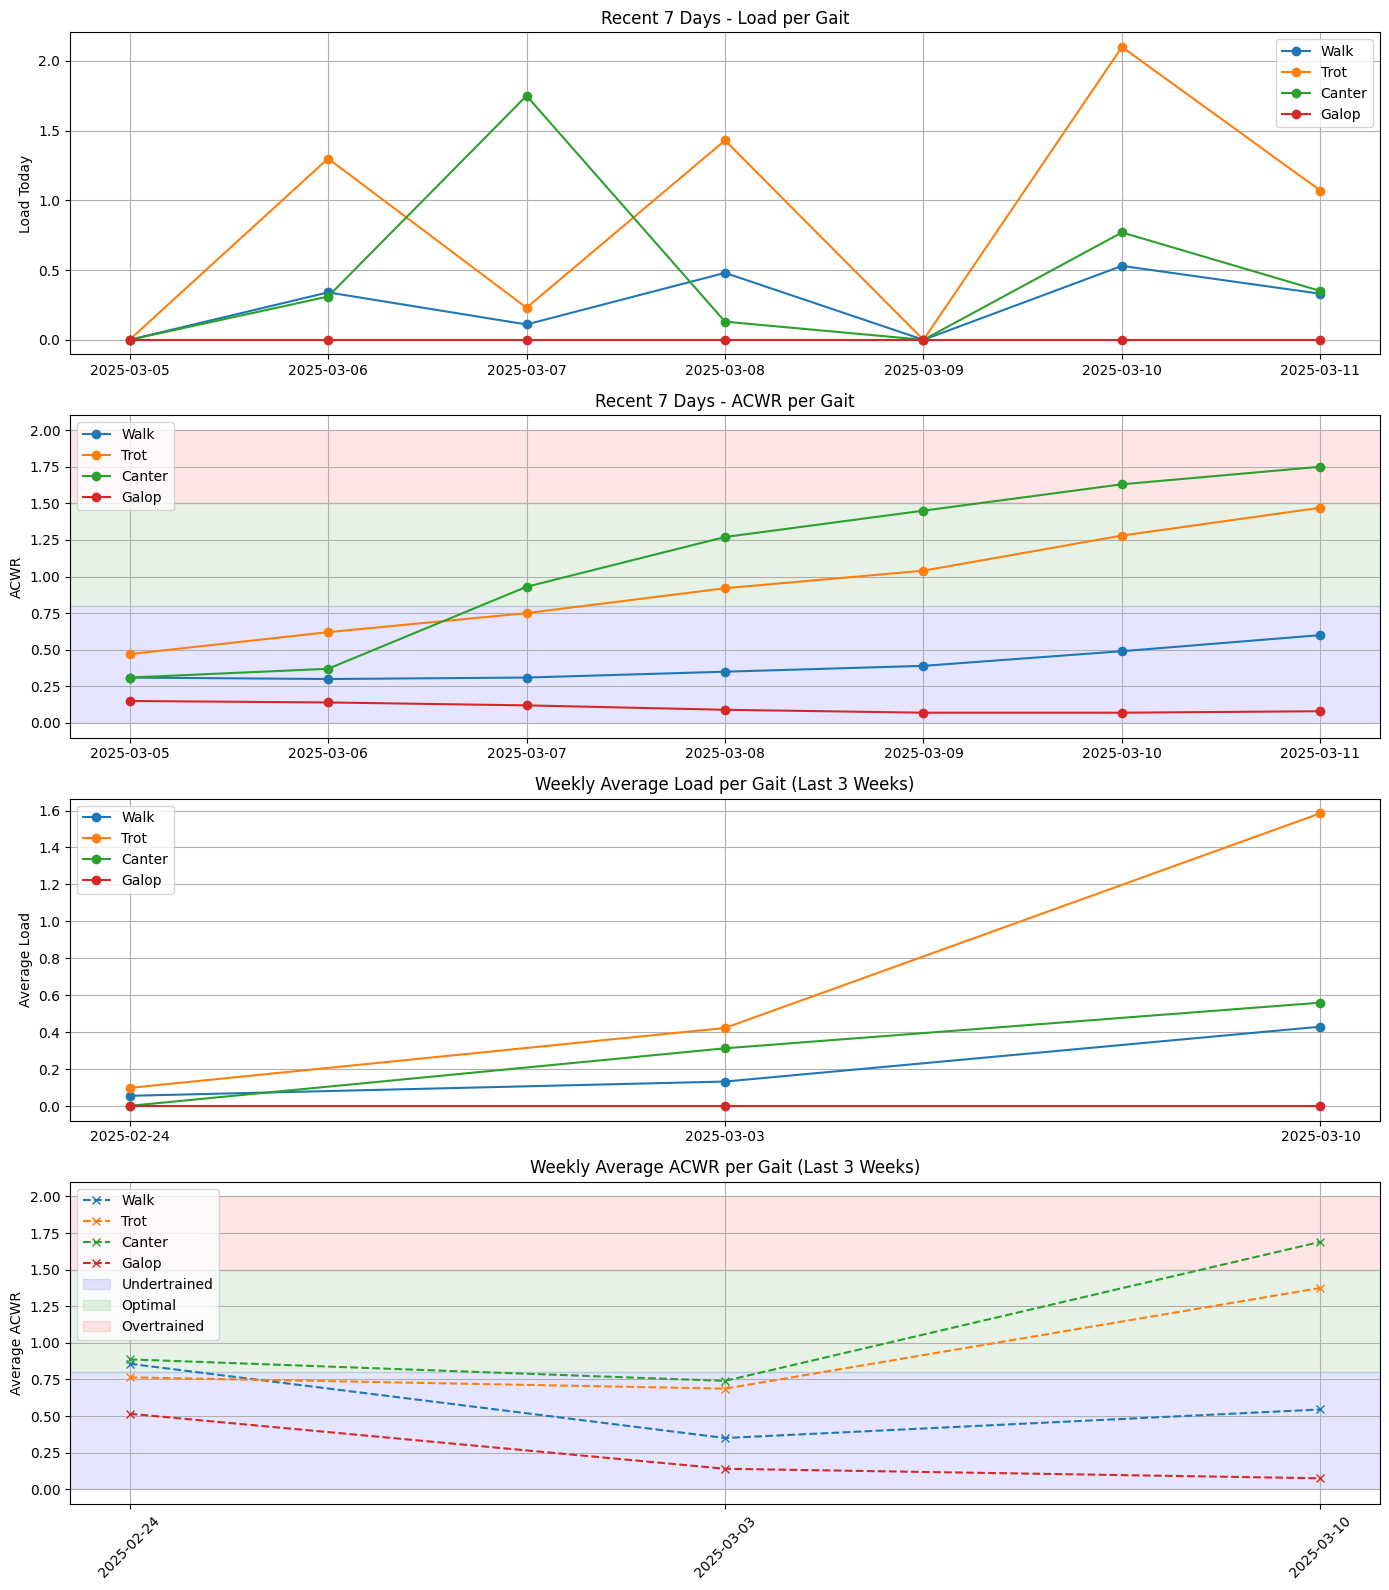

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_training_summary(df_horse):
    df_horse = df_horse.sort_values("Date")
    gaits = ["walk", "trot", "canter", "galop"]
    
    # --- PREPARE DATA ---
    df_recent = df_horse.tail(7)
    dates = df_recent["Date"].dt.strftime("%Y-%m-%d")

    df_horse["Week"] = df_horse["Date"].dt.to_period("W").apply(lambda r: r.start_time)
    last_3_weeks = df_horse["Week"].dropna().unique()[-3:]
    df_weekly = df_horse[df_horse["Week"].isin(last_3_weeks)]

    weekly_agg = df_weekly.groupby("Week").agg({
        **{f"iTrimp_{g}_Load_Today": 'mean' for g in gaits},
        **{f"iTrimp_{g}_ACWR": 'mean' for g in gaits}
    }).reset_index()
    weeks = weekly_agg["Week"].dt.strftime('%Y-%m-%d')

    # --- PLOTS ---
    fig, axs = plt.subplots(4, 1, figsize=(14, 16), sharex=False)

    # 1. Daily Load (7 days)
    for gait in gaits:
        axs[0].plot(dates, df_recent[f"iTrimp_{gait}_Load_Today"], marker='o', label=gait.capitalize())
    axs[0].set_ylabel("Load Today")
    axs[0].set_title("Recent 7 Days - Load per Gait")
    axs[0].legend()
    axs[0].grid(True)

    # 2. Daily ACWR (7 days)
    for gait in gaits:
        axs[1].plot(dates, df_recent[f"iTrimp_{gait}_ACWR"], marker='o', label=gait.capitalize())
    axs[1].axhspan(0, 0.8, color='blue', alpha=0.1)
    axs[1].axhspan(0.8, 1.5, color='green', alpha=0.1)
    axs[1].axhspan(1.5, 2.0, color='red', alpha=0.1)
    axs[1].set_ylabel("ACWR")
    axs[1].set_title("Recent 7 Days - ACWR per Gait")
    axs[1].legend()
    axs[1].grid(True)

    # 3. Weekly Average Load
    for gait in gaits:
        axs[2].plot(weeks, weekly_agg[f"iTrimp_{gait}_Load_Today"], marker='o', label=gait.capitalize())
    axs[2].set_title("Weekly Average Load per Gait (Last 3 Weeks)")
    axs[2].set_ylabel("Average Load")
    axs[2].legend()
    axs[2].grid(True)

    # 4. Weekly Average ACWR
    for gait in gaits:
        axs[3].plot(weeks, weekly_agg[f"iTrimp_{gait}_ACWR"], marker='x', linestyle='--', label=gait.capitalize())
    axs[3].axhspan(0, 0.8, color='blue', alpha=0.1, label='Undertrained')
    axs[3].axhspan(0.8, 1.5, color='green', alpha=0.1, label='Optimal')
    axs[3].axhspan(1.5, 2.0, color='red', alpha=0.1, label='Overtrained')
    axs[3].set_title("Weekly Average ACWR per Gait (Last 3 Weeks)")
    axs[3].set_ylabel("Average ACWR")
    axs[3].legend()
    axs[3].grid(True)
    axs[3].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

plot_training_summary(df_horse)

Here is also graphical representation of the inputed data for `Load` and `ACWR`.

In [20]:
# Pass to Mistral model for feedback
#feedback = generate_local_feedback(summary_text)
#print("\nFeedback for trainer:")
#print(feedback)



###  **Conclusion: Personalized Equine Training Feedback System**

In this project, we developed a data-driven approach to **analyze horse training patterns** and generate **personalized, expert-level feedback** for trainers. The core objective was to ensure each horse's workload is optimized for health and performance, using **ACWR (Acute\:Chronic Workload Ratio)** and daily training loads across different gaits (walk, trot, canter, galop).

####  Key Steps in the Process:

1. **Data Selection & Filtering**
   We isolated training data for individual horses and ensured only complete, valid rows were used for analysis.

2. **Metric Summarization**
   For the **recent 7 days**, we created summaries that included daily load, ACWR, and risk zones to assess training adequacy per gait.

3. **Risk Zone Classification**
   Using scientifically accepted thresholds:

   * ACWR < 0.8 → **Undertrained**
   * 0.8 ≤ ACWR ≤ 1.5 → **Optimal**
   * ACWR > 1.5 → **Overtrained**

4. **Visualizations**
   We enhanced interpretability by plotting **daily load and ACWR trends**, highlighting fluctuations and risk zones clearly for each gait.

5. **Feedback Generation**
   A structured natural language prompt was crafted and passed to a local language model (via Ollama and Mistral), which generated **human-readable, supportive, and actionable feedback** tailored to the horse’s specific data patterns.

####  Benefits of This Approach:

* Offers **objective, evidence-based feedback** for trainers.
* Identifies **undertraining, overtraining, or erratic patterns** early to prevent injuries or performance drops.
* Helps tailor **gait-specific recommendations**.
* Supports **decision-making for rest or load adjustments** with confidence.
* Lays a foundation for **scalable, automated equine performance monitoring**.

---

####  Limitations:

1. **Model Performance & Hardware Dependency**

   * The feedback generation process relies on local large language models (like Mistral via Ollama), which require **significant system resources**, particularly **a strong GPU** for reasonable runtime performance.
   * On lower-end systems, the generation may be **slow or unresponsive**, impacting real-time usability.

2. **Feedback Validity & Scientific Rigor**

   * While the language model provides **expert-style output**, it does **not perform real scientific validation** of the suggestions.
   * The generated feedback may **lack clinical vetting**, and thus should be **reviewed by qualified equine professionals** before implementation.

3. **Limited Context Awareness**

   * The model is **only as good as the input summary** it receives. If the summary lacks context (e.g. competition schedule, medical history), the feedback may miss important nuances.

4. **No Learning or Feedback Loop**

   * The model does **not learn over time** or adapt based on previous feedback accuracy or outcomes. This limits personalization unless explicitly integrated in future iterations.

---
